In [1]:
import re
from pathlib import Path

import csv
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

matplotlib.rcParams["font.family"] = "DM Sans"

In [9]:
# --- Load and parse CSV ---
csv_path = "/home/mila/a/aidan.sirbu/SCAMPER/data/treats_collected.csv"

# Pattern: Tminr<radius>_<mode>_s<seed>_<runID>
run_pattern = re.compile(r"^Tminr([\d.]+)_(.+)_s(\d+)_\d+_\d+_\d+$")

records = []

with open(csv_path) as f:
    reader = csv.reader(f)
    header = next(reader)

    # Find columns for each run's metric (exclude __MIN/__MAX)
    runs = {}
    for i, col in enumerate(header):
        if (
            col.endswith(" - eval/episode_mean_collected_treats")
            and not col.endswith("__MIN")
            and not col.endswith("__MAX")
        ):
            run_name = col.split(" - ")[0]
            runs[run_name] = i

    rows = list(reader)

    for run_name, col_idx in runs.items():
        # Get max treats across all timesteps for this run
        values = [float(row[col_idx]) for row in rows if row[col_idx].strip()]
        if not values:
            continue
        max_treats = max(values)

        m = run_pattern.match(run_name)
        if m:
            radius = float(m.group(1))
            mode = m.group(2)
            seed = int(m.group(3))
            records.append(
                {
                    "radius": radius,
                    "training_mode": mode,
                    "seed": seed,
                    "collected_treats": max_treats,
                }
            )

df = pd.DataFrame(records)

# Rename training modes
mode_rename = {
    "distill_prior": "SCAMPER",
    "distill_prior_no_rgm": "Motion Prior Only",
    "decoder_only": "MIMIC-MJX",
    "scratch": "Scratch",
}
df["Training Mode"] = df["training_mode"].map(mode_rename)

print(f"{len(df)} runs loaded")
df.head()

112 runs loaded


,radius,training_mode,seed,collected_treats,Training Mode
0,1.50,distill_prior_no_rgm,3,0.0,Motion Prior Only
1,1.50,distill_prior_no_rgm,0,0.0,Motion Prior Only
2,1.50,distill_prior_no_rgm,1,0.0,Motion Prior Only
3,1.50,distill_prior_no_rgm,2,0.0,Motion Prior Only
4,1.25,distill_prior_no_rgm,1,0.0,Motion Prior Only


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/arena_forage_collected_treats.[pdf|svg|png]


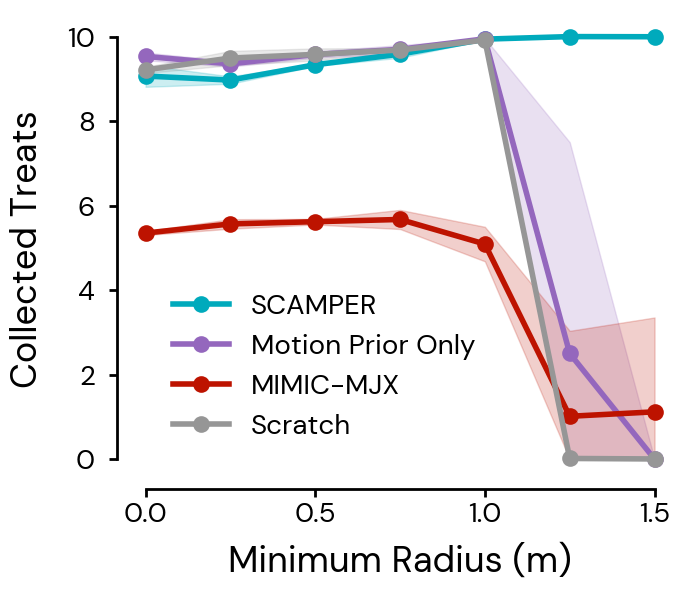

In [12]:
hue_order = ["SCAMPER", "Motion Prior Only", "MIMIC-MJX", "Scratch"]
palette = {
    "SCAMPER": tuple(c / 255 for c in (0, 170, 188)),
    "Motion Prior Only": tuple(c / 255 for c in (148, 103, 189)),
    "MIMIC-MJX": tuple(c / 255 for c in (189, 19, 0)),
    "Scratch": tuple(c / 255 for c in (150, 150, 150)),
}

save_name = "arena_forage_collected_treats"

fig, ax_main = plt.subplots(figsize=(7, 6))

# --- Main plot ---
sns.lineplot(
    data=df,
    x="radius",
    y="collected_treats",
    hue="Training Mode",
    hue_order=hue_order,
    palette=palette,
    errorbar="sd",
    marker="o",
    markersize=12,
    markeredgewidth=0,
    linewidth=4,
    ax=ax_main,
)

# Clip error band shading to y >= 0
for child in ax_main.get_children():
    if isinstance(child, plt.matplotlib.collections.PolyCollection):
        paths = child.get_paths()
        for path in paths:
            path.vertices[:, 1] = np.clip(path.vertices[:, 1], 0, None)

ax_main.set_ylim(bottom=-0.7)
ax_main.set_xlabel("Minimum Radius (m)", fontsize=26, labelpad=12)
ax_main.set_ylabel("Collected Treats", fontsize=26, labelpad=16)
ax_main.tick_params(labelsize=20, width=2, length=6)
ax_main.tick_params(axis="y", pad=10)

# Remove top and right spines
sns.despine(ax=ax_main)

# Trim spines to data range
xticks = ax_main.get_xticks()
yticks = ax_main.get_yticks()
xlim = ax_main.get_xlim()
ylim = ax_main.get_ylim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
yticks = [t for t in yticks if ylim[0] <= t <= ylim[1]]

ax_main.spines["bottom"].set_bounds(xticks[0], xticks[-1])
ax_main.spines["left"].set_bounds(yticks[0], yticks[-1])

# Shift y-axis spine to the left
ax_main.spines["left"].set_position(("outward", 2))

# Thicken the remaining spines
for spine in ["left", "bottom"]:
    ax_main.spines[spine].set_linewidth(2)

ax_main.legend(
    fontsize=20, frameon=False, loc="lower left", bbox_to_anchor=(0.05, 0.05)
)

plt.tight_layout()

# Save
save_dir = Path(
    "/home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots"
)
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"{save_name}.pdf", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.svg", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.png", bbox_inches="tight")
print(f"Saved to {save_dir / save_name}.[pdf|svg|png]")

plt.show()